<a href="https://colab.research.google.com/github/luciachacon6445/Deep-learning-para-visi-n-por-computadoras/blob/main/Segmentacion_semantica_UNet_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Deep Learning para visión de computadoras
##Lab 2.2 Segmentación semántica

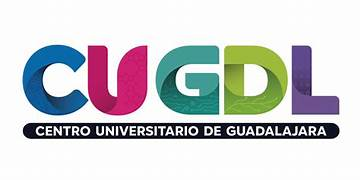

# Objetivo
Calcular IoU por clase y mIoU a mano a partir de la matriz de confusión y verificar con torchmetrics.
Construir una U-Net desde cero y medir qué aportan las conexiones de salto.
Comparar tres funciones de pérdida: entropía cruzada, Dice y su combinación.
Secuencias de video: CNN estática vs. CNN-LSTM

In [ ]:
%pip install -q torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 21.2 MB/s eta 0:00:00


In [ ]:
import time, copy
import os
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Dataset, Subset
import torchmetrics
import torchvision
import torchvision.transforms as T
from torchmetrics.classification import MulticlassJaccardIndex, MulticlassConfusionMatrix

SEED = 2
def fijar_semilla(s=SEED):
    np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
fijar_semilla()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, "·", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU (más lento, pero funciona)")
print("torch", torch.__version__, "· torchmetrics", torchmetrics.__version__)

NOMBRES = ["fondo", "círculo", "cuadrado", "triángulo"]
N_CLASES = len(NOMBRES)
TAM = 64                       # las imágenes son de 64 x 64 píxeles

Dispositivo: cuda · Tesla T4
torch 2.11.0+cu130 · torchmetrics 1.9.0


---
# PARTE A

En clasificación, una imagen tiene **una** etiqueta. En segmentación semántica, una imagen de $H\times W$ tiene **$H\cdot W$ etiquetas**:

El conjunto de datos de mascotas Oxford- IIIT ( Parkhi et al, 2012 ). El conjunto de datos consta de imágenes de 37 razas de mascotas, con 200 imágenes por raza (~100 cada una en las divisiones de entrenamiento y prueba). Cada imagen incluye las etiquetas correspondientes y las máscaras de píxeles.

    El dataset contiene imágenes de mascotas y máscaras de segmentación de 3 clases:
    
    Clase 1: Mascota (Foreground)
    Clase 2: Fondo (Background)
    Clase 3: Borde / Contorno ambiguo\

In [ ]:
TAM = 128
NOMBRES_CLASES = ["Mascota", "Fondo", "Borde"]
N_CLASES = len(NOMBRES_CLASES)

# Transformación para la imagen (RGB -> Normalización estándar de ImageNet)
transform_img = T.Compose([
    T.Resize((TAM, TAM)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transformación para la máscara (Interpolación NEAREST para preservar enteros) reescalado, garantizando que no se generen valores intermedios artificiales entre categorías.
#Por conveniencia, reste 1 de la máscara de segmentación, lo que da como resultado etiquetas que son: {0, 1, 2}.
def transform_mask(mask):
    mask = mask.resize((TAM, TAM), resample=Image.NEAREST)
    mask_arr = np.array(mask, dtype=np.int64) - 1  # Pasar de {1,2,3} a {0,1,2}
    return torch.as_tensor(mask_arr, dtype=torch.long)

# Descargar dataset oficial vía torchvision
train_raw = torchvision.datasets.OxfordIIITPet(
    root="./data", split="trainval", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)
test_raw = torchvision.datasets.OxfordIIITPet(
    root="./data", split="test", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)

# Subconjuntos optimizados para una sesión interactiva de clase (rápida convergencia)
train_ds = Subset(train_raw, range(1000))
val_ds = Subset(test_raw, range(250))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)

print(f"Imágenes de entrenamiento: {len(train_ds)} | Validación: {len(val_ds)}")

100%|██████████| 792M/792M [00:31<00:00, 25.5MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.0MB/s]


Imágenes de entrenamiento: 1000 | Validación: 250


máscaras reales codificadas mediante un mapa de color cualitativo (Verde = Mascota, Negro = Fondo, Rojo = Borde):

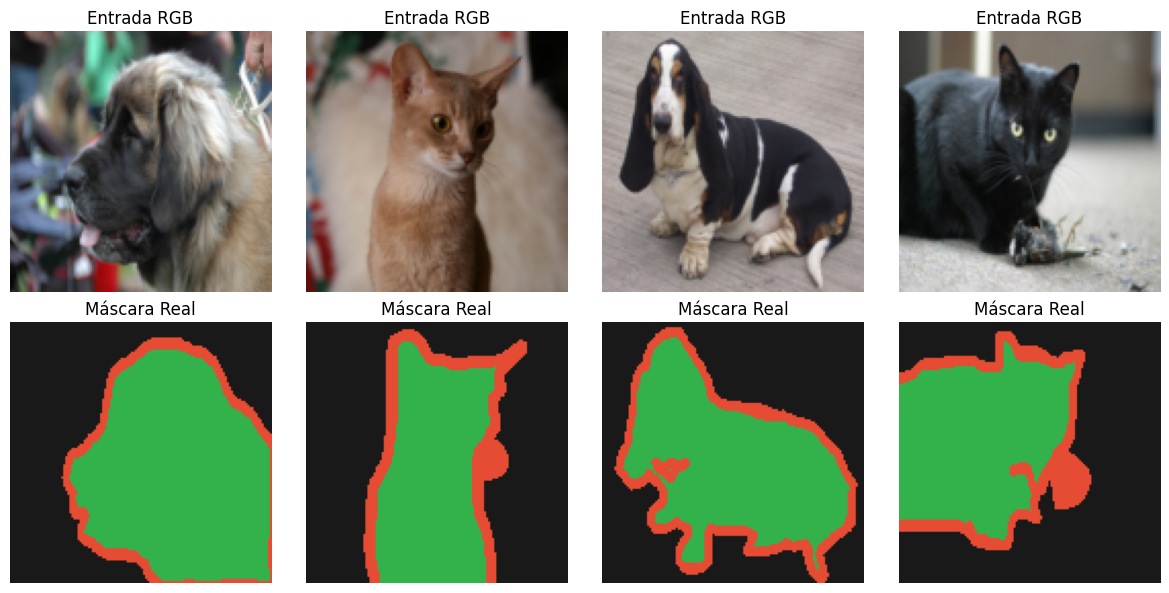

In [ ]:
def desnormalizar(tensor):
    img = tensor.clone().cpu().permute(1, 2, 0).numpy()
    img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    return np.clip(img, 0, 1)

PALETA_PETS = np.array([[0.2, 0.7, 0.3], [0.1, 0.1, 0.1], [0.9, 0.3, 0.2]])

imgs, masks = next(iter(train_loader))
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Máscara Real")
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

# 2. ARQUITECTURA DE LA RED: U-NET COMPACTA DESDE CEROLa red implementa una estructura simétrica compuesta por:   

1.   Bloque Doble de Convolución: Encapsula la secuencia $\text {Conv2D} \rightarrow \text{BatchNorm} \rightarrow \text{ReLU}$ por duplicado, manteniendo dimensiones espaciales mediante relleno (padding $= 1$).

2.   Trayectoria de Contracción (Encoder): Reduce periódicamente la resolución a la mitad con operaciones de agrupamiento máximo (MaxPool2d) mientras incrementa la profundidad de canales semánticos.   
3. Cuello de Botella (Bottleneck): El punto de mayor compresión espacial ($16 \times 16$) y máxima abstracción de características.   
4. Trayectoria de Expansión (Decoder): Aplica convoluciones transpuestas (ConvTranspose2d) con factor de escala $\times 2$ y realiza la fusión por concatenación (torch.cat) de las activaciones correspondientes del codificador.   
5. Capa de Salida: Una convolución $1 \times 1$ que reduce los 32 canales residuales a 3 logits correspondientes a las clases del problema.  

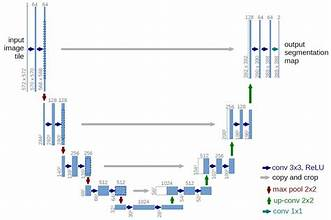

In [ ]:
class BloqueDobleConv(nn.Module):
    """(Conv2d -> BatchNorm -> ReLU) * 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)

class UNetCompacta(nn.Module):
    def __init__(self, in_channels=3, num_classes=3):
        super().__init__()
        # --- ENCODER ---
        self.enc1 = BloqueDobleConv(in_channels, 32)      # Entrada: 128x128
        self.pool1 = nn.MaxPool2d(2, 2)                   # -> 64x64

        self.enc2 = BloqueDobleConv(32, 64)               # -> 64x64
        self.pool2 = nn.MaxPool2d(2, 2)                   # -> 32x32

        self.enc3 = BloqueDobleConv(64, 128)              # -> 32x32
        self.pool3 = nn.MaxPool2d(2, 2)                   # -> 16x16

        # --- BOTTLENECK ---
        self.bottleneck = BloqueDobleConv(128, 256)       # -> 16x16

        # --- DECODER & SKIP CONNECTIONS ---
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2) # -> 32x32
        self.dec3 = BloqueDobleConv(256, 128)             # 128 (skip) + 128 = 256

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # -> 64x64
        self.dec2 = BloqueDobleConv(128, 64)              # 64 (skip) + 64 = 128

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # -> 128x128
        self.dec1 = BloqueDobleConv(64, 32)               # 32 (skip) + 32 = 64

        # Proyección final lineal a nivel de píxel
        self.out_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Paso por el Encoder
        s1 = self.enc1(x)
        p1 = self.pool1(s1)

        s2 = self.enc2(p1)
        p2 = self.pool2(s2)

        s3 = self.enc3(p2)
        p3 = self.pool3(s3)

        # Cuello de botella
        b = self.bottleneck(p3)

        # Paso por el Decoder con Skip Connections (torch.cat)
        d3 = self.up3(b)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        return self.out_conv(d1)

modelo = UNetCompacta(in_channels=3, num_classes=3).to(DEVICE)
print("Arquitectura instanciada. Parámetros totales:", sum(p.numel() for p in modelo.parameters()))

Arquitectura instanciada. Parámetros totales: 1927075


---
# PARTE B

Sean $TP_c$, $FP_c$, $FN_c$ los píxeles de la clase $c$ acertados, falsamente asignados a $c$ y omitidos, respectivamente. Para cada clase:

$$\mathrm{IoU}_c=\frac{TP_c}{TP_c+FP_c+FN_c}\qquad \mathrm{Dice}_c=\frac{2\,TP_c}{2\,TP_c+FP_c+FN_c}\qquad \mathrm{mIoU}=\frac{1}{C}\sum_{c=1}^{C}\mathrm{IoU}_c$$

Todo sale de la **matriz de confusión** de píxeles: la diagonal contiene los $TP_c$; la suma de la fila $c$ menos la diagonal son los $FN_c$; la suma de la columna $c$ menos la diagonal son los $FP_c$. Aquí las filas son la clase real y las columnas la predicha.

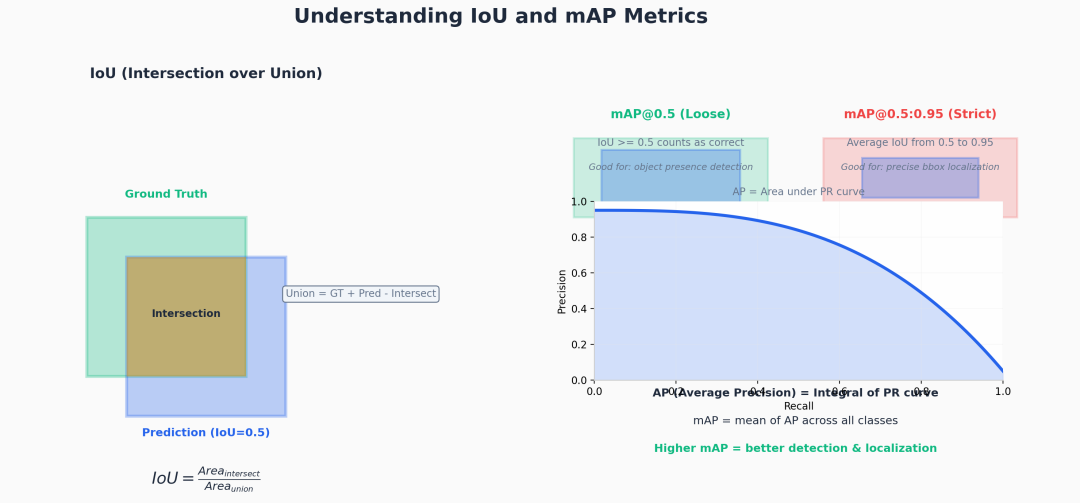

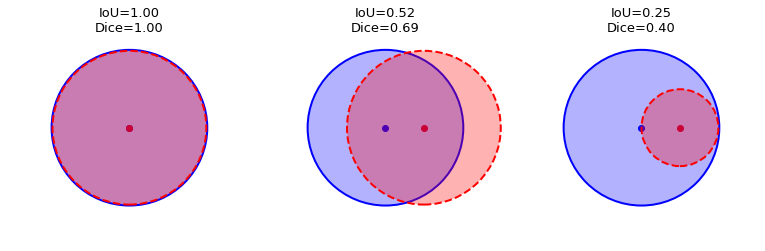

Revisar: https://ilmonteux.github.io/2019/05/10/segmentation-metrics.html


Para optimizar adecuadamente la segmentación semántica frente al desbalance de clases (por ejemplo, el borde contiene considerablemente menos píxeles que el fondo), se combinan dos objetivos complementarios:   

Cross-Entropy Loss ($\mathcal{L}_{\text{CE}}$): Evalúa la distribución de probabilidad generada independientemente en cada posición $(i, j)$ del mapa de píxeles.   

Dice Loss ($\mathcal{L}_{\text{Dice}}$): Mide el solapamiento volumétrico entre la máscara binarizada y la predicción probabilística:

   $$\text{Dice} = \frac{2 \vert{}P \cap T\vert{}}{\vert{}P\vert{} + \vert{}T\vert{}} = \frac{2 \sum p_i t_i}{\sum p_i^2 + \sum t_i^2}$$   Pérdida Híbrida Total:$$\mathcal{L}_{\text{Total}} = \mathcal{L}_{\text{CE}} + \mathcal{L}_{\text{Dice}}$$

In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, targets):
        num_classes = logits.shape[1]
        probs = F.softmax(logits, dim=1)

        # One-hot encoding de targets a dimensiones [B, C, H, W]
        targets_one_hot = F.one_hot(targets, num_classes=num_classes).permute(0, 3, 1, 2).float()

        # Aplanar dimensiones espaciales para el cálculo vectorial
        probs = probs.contiguous().view(probs.shape[0], num_classes, -1)
        targets_one_hot = targets_one_hot.contiguous().view(targets_one_hot.shape[0], num_classes, -1)

        interseccion = (probs * targets_one_hot).sum(dim=2)
        union = probs.sum(dim=2) + targets_one_hot.sum(dim=2)

        dice = (2. * interseccion + self.eps) / (union + self.eps)
        return 1.0 - dice.mean()

# Instanciación de pérdidas
ce_fn = nn.CrossEntropyLoss()
dice_fn = DiceLoss()

def loss_combinada(logits, targets):
    return ce_fn(logits, targets) + dice_fn(logits, targets)

,Clase,Píxeles,Porcentaje (%)
0,Mascota,4684013,28.59
1,Fondo,9738252,59.44
2,Borde,1961735,11.97


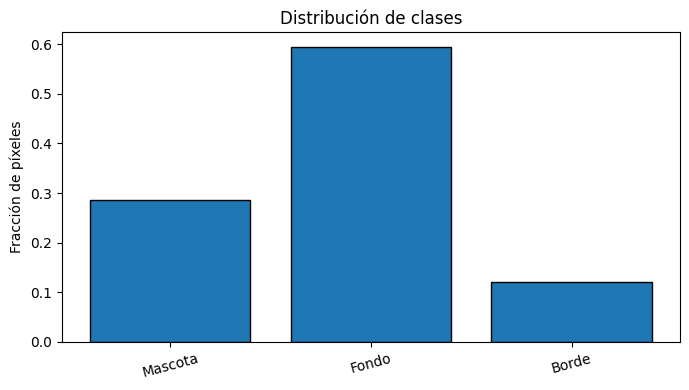

In [ ]:
# Distribución de píxeles por clase
conteo = torch.zeros(N_CLASES, dtype=torch.long)

for _, mascara in train_ds:
    conteo += torch.bincount(
        mascara.long().flatten(),
        minlength=N_CLASES
    )

conteo = conteo.numpy()
frecuencias = conteo / conteo.sum()

tabla_px = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "Píxeles": conteo,
    "Porcentaje (%)": (frecuencias * 100).round(2)
})

display(tabla_px)

plt.figure(figsize=(7, 4))
plt.bar(NOMBRES_CLASES, frecuencias, edgecolor="black")
plt.ylabel("Fracción de píxeles")
plt.title("Distribución de clases")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
# Calcular pesos inversamente proporcionales a la frecuencia
pesos = 1.0 / np.sqrt(np.maximum(frecuencias, 1e-8))
pesos = pesos / pesos.mean()

pesos_tensor = torch.tensor(
    pesos,
    dtype=torch.float32,
    device=DEVICE
)

print("Pesos por clase:")
for nombre, peso in zip(NOMBRES_CLASES, pesos):
    print(f"{nombre}: {peso:.4f}")

Pesos por clase:
Mascota: 0.9263
Fondo: 0.6424
Borde: 1.4313


In [ ]:
ce_fn_ponderada = nn.CrossEntropyLoss(reduction="none")

def loss_combinada_ponderada(logits, targets):
    targets = targets.long()

    # Cross-Entropy por píxel
    perdida_pixel = ce_fn_ponderada(logits, targets)

    # Peso según la clase real
    pesos_pixel = pesos_tensor[targets]

    # Pérdida ponderada
    perdida_ce = (perdida_pixel * pesos_pixel).mean()

    # Conservar Dice Loss
    perdida_dice = dice_fn(logits, targets)

    return perdida_ce + perdida_dice

#ENTRENAMIENTO

In [ ]:
# Inicializar una U-Net nueva
modelo = UNetCompacta(
    in_channels=3,
    num_classes=N_CLASES
).to(DEVICE)

EPOCHS = 6
optimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=1e-3
)

print("--- Entrenamiento U-Net con pérdida ponderada ---")

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    modelo.train()
    loss_acumulada = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(DEVICE)
        masks = masks.to(DEVICE).long()

        optimizador.zero_grad()
        logits = modelo(imgs)

        loss = loss_combinada_ponderada(logits, masks)

        loss.backward()
        optimizador.step()

        loss_acumulada += loss.item()

    loss_promedio = loss_acumulada / len(train_loader)
    tiempo_epoca = time.time() - t0

    print(
        f"Época {epoch}/{EPOCHS} | "
        f"Loss ponderada: {loss_promedio:.4f} | "
        f"Tiempo: {tiempo_epoca:.1f}s"
    )

--- Entrenamiento U-Net con pérdida ponderada ---
Época 1/6 | Loss ponderada: 1.2504 | Tiempo: 8.9s
Época 2/6 | Loss ponderada: 0.9552 | Tiempo: 5.4s
Época 3/6 | Loss ponderada: 0.8510 | Tiempo: 5.5s
Época 4/6 | Loss ponderada: 0.7829 | Tiempo: 5.5s
Época 5/6 | Loss ponderada: 0.7462 | Tiempo: 5.5s
Época 6/6 | Loss ponderada: 0.7116 | Tiempo: 5.5s


In [ ]:
"""

EPOCHS = 6
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

print("--- Iniciando Entrenamiento U-Net ---")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    modelo.train()
    loss_acumulada = 0.0

    for imgs, masks in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        optimizador.zero_grad()
        logits = modelo(imgs)
        loss = loss_combinada(logits, masks)
        loss.backward()
        optimizador.step()

        loss_acumulada += loss.item()

    tiempo_epoca = time.time() - t0
    loss_promedio = loss_acumulada / len(train_loader)
    print(f"Época {epoch}/{EPOCHS} | Loss: {loss_promedio:.4f} | Tiempo: {tiempo_epoca:.1f}s")

    """

'\n\nEPOCHS = 6\noptimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)\n\nprint("--- Iniciando Entrenamiento U-Net ---")\nfor epoch in range(1, EPOCHS + 1):\n    t0 = time.time()\n    modelo.train()\n    loss_acumulada = 0.0\n\n    for imgs, masks in train_loader:\n        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)\n\n        optimizador.zero_grad()\n        logits = modelo(imgs)\n        loss = loss_combinada(logits, masks)\n        loss.backward()\n        optimizador.step()\n\n        loss_acumulada += loss.item()\n\n    tiempo_epoca = time.time() - t0\n    loss_promedio = loss_acumulada / len(train_loader)\n    print(f"Época {epoch}/{EPOCHS} | Loss: {loss_promedio:.4f} | Tiempo: {tiempo_epoca:.1f}s")\n\n    '

IoU, mIoU Y MATRIZ DE CONFUSIÓN

Calculo de forma desacoplada el índice de Jaccard (Intersection over Union) para cada una de las clases, su promedio macro (mIoU) y la matriz de confusión espacial de píxeles empleando torchmetrics:   $$\text{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}$$

In [ ]:
metric_iou_clase = MulticlassJaccardIndex(num_classes=N_CLASES, average=None).to(DEVICE)
metric_iou_macro = MulticlassJaccardIndex(num_classes=N_CLASES, average="macro").to(DEVICE)
metric_confusion = MulticlassConfusionMatrix(num_classes=N_CLASES).to(DEVICE)

metric_iou_clase.reset()
metric_iou_macro.reset()
metric_confusion.reset()

modelo.eval()
with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = modelo(imgs)
        preds = logits.argmax(dim=1)

        metric_iou_clase.update(preds, masks)
        metric_iou_macro.update(preds, masks)
        metric_confusion.update(preds, masks)

ious = metric_iou_clase.compute().cpu().numpy()
miou = metric_iou_macro.compute().item()
cm = metric_confusion.compute().cpu().numpy()

tabla_eval = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "IoU (Jaccard)": [round(val, 4) for val in ious]
})
display(tabla_eval)
print(f"\nMean IoU (mIoU): {miou:.4f}")

print("\nMatriz de Confusión de Píxeles:\n", cm)

,Clase,IoU (Jaccard)
0,Mascota,0.6233
1,Fondo,0.7881
2,Borde,0.4166



Mean IoU (mIoU): 0.6094

Matriz de Confusión de Píxeles:
 [[ 850928  202480  121065]
 [ 102099 2124337  134977]
 [  88544  131546  340024]]


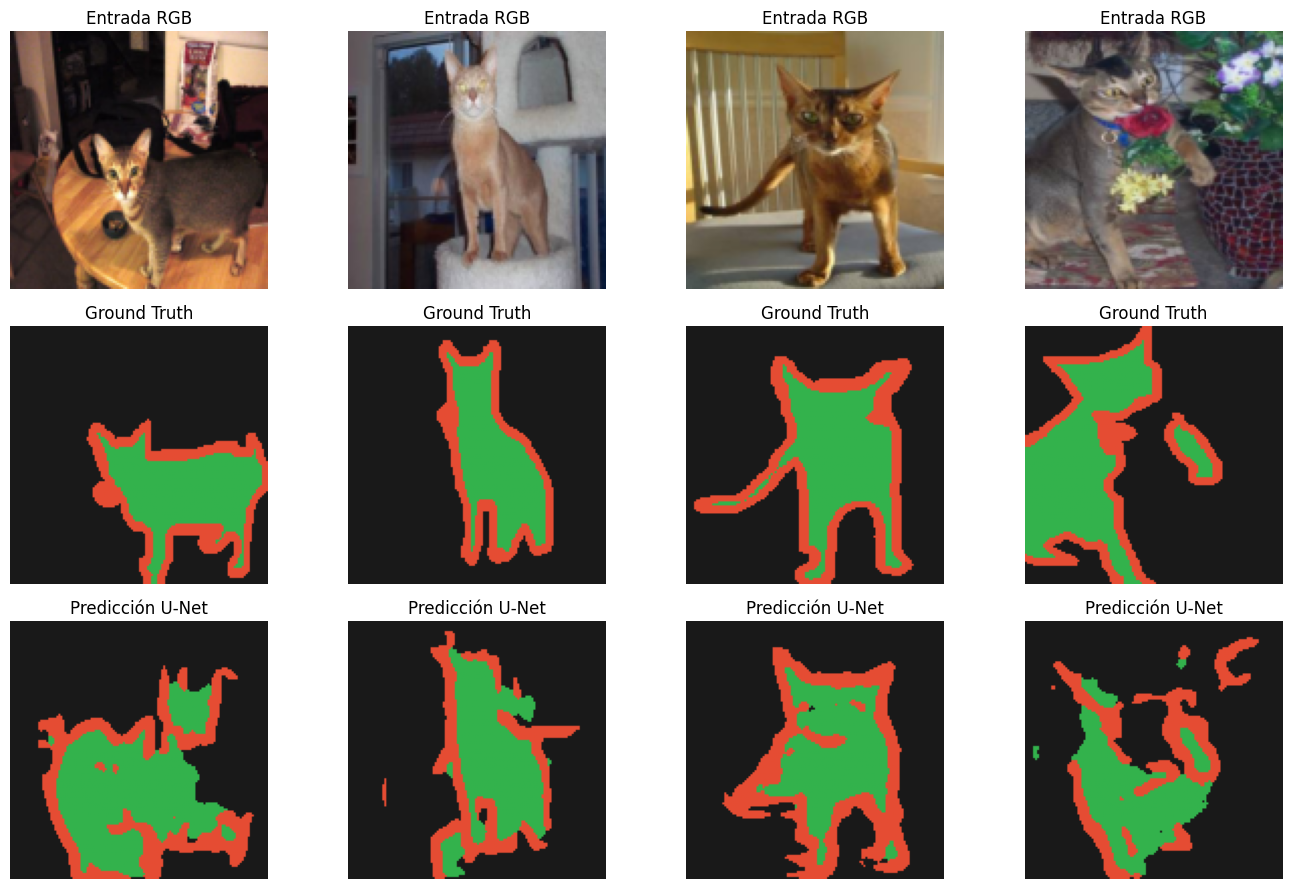

In [ ]:
imgs, masks = next(iter(val_loader))
imgs_dev = imgs.to(DEVICE)

modelo.eval()
with torch.no_grad():
    preds = modelo(imgs_dev).argmax(dim=1).cpu()

fig, axs = plt.subplots(3, 4, figsize=(14, 9))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Ground Truth")
    axs[1, i].axis("off")

    axs[2, i].imshow(PALETA_PETS[preds[i].numpy()])
    axs[2, i].set_title("Predicción U-Net")
    axs[2, i].axis("off")
plt.tight_layout()
plt.show()

### Actividad
Clases desequilibradas y ponderación de clases

Los conjuntos de datos para segmentación semántica pueden estar muy desequilibrados; esto significa que los píxeles correspondientes a determinadas clases pueden aparecer con mayor frecuencia en las imágenes que los de otras clases. Dado que los problemas de segmentación pueden abordarse como problemas de clasificación a nivel de píxel, es posible gestionar este desequilibrio mediante la ponderación de la función de pérdida. Se trata de una solución sencilla y elegante para este tipo de situaciones. Para obtener más información, consulte el tutorial sobre [Classification on imbalanced data](../structured_data/imbalanced_data.ipynb) tutorial to learn more.

To [avoid ambiguity](https://github.com/keras-team/keras/issues/3653#issuecomment-243939748), `Model.fit` does not support the `class_weight` argument for targets with 3+ dimensions.

La exactitud de píxeles no es suficiente para evaluar la segmentación semántica cuando existe un desequilibrio entre clases, ya que calcula la proporción total de píxeles clasificados correctamente sin considerar el rendimiento de cada categoría.

En este caso, Fondo representa el 59.44% de los píxeles, mientras que Borde solo representa el 11.97%, por esto el modelo podría obtener una exactitud alta al clasificar correctamente la mayoría de los píxeles del fondo, aunque tenga dificultades para identificar los bordes.

Por esta razón, es importante complementar la exactitud con el IoU por clase y el mIoU, ya que permiten evaluar de forma más equilibrada el rendimiento de la segmentación.

### Actividad
Otros datasets
[Carvana](https://www.kaggle.com/c/carvana-image-masking-challenge/overview) image masking challenge hosted on Kaggle.

DSB 2018
# https://datasets.simula.no/kvasir-seg/
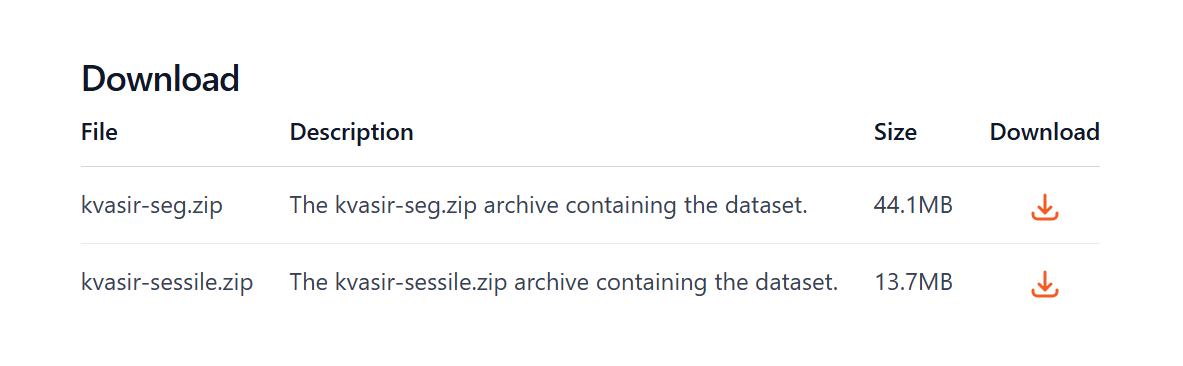

In [ ]:
!unzip -q -o "/content/kvasir-seg" -d ./dsb2018


[/content/kvasir-seg.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/kvasir-seg or
        /content/kvasir-seg.zip, and cannot find /content/kvasir-seg.ZIP, period.


In [ ]:
import zipfile
import os

ruta_zip = "/content/kvasir-seg.zip"
destino = "/content/kvasir_seg"

with zipfile.ZipFile(ruta_zip, "r") as archivo:
    print("Primeros archivos:", archivo.namelist()[:10])
    archivo.extractall(destino)

print("Extracción terminada.")
print("Contenido:", os.listdir(destino)[:10])

Primeros archivos: ['Kvasir-SEG/', 'Kvasir-SEG/kavsir_bboxes.json', 'Kvasir-SEG/images/', 'Kvasir-SEG/images/ck2bxiswtxuw80838qkisqjwz.jpg', 'Kvasir-SEG/images/ck2bxknhjvs1x0794iogrq49k.jpg', 'Kvasir-SEG/images/ck2bxlujamu330725szlc2jdu.jpg', 'Kvasir-SEG/images/ck2bxpfgxu2mk0748gsh7xelu.jpg', 'Kvasir-SEG/images/ck2bxqz3evvg20794iiyv5v2m.jpg', 'Kvasir-SEG/images/ck2bxskgxxzfv08386xkqtqdy.jpg', 'Kvasir-SEG/images/ck2bxw18mmz1k0725litqq2mc.jpg']
Extracción terminada.
Contenido: ['Kvasir-SEG']


In [ ]:
import os

BASE_KVASIR = "/content/kvasir_seg/Kvasir-SEG"

for carpeta, subcarpetas, archivos in os.walk(BASE_KVASIR):
    nivel = carpeta.replace(BASE_KVASIR, "").count(os.sep)

    if nivel <= 2:
        print(
            f"{carpeta} | "
            f"Subcarpetas: {subcarpetas[:5]} | "
            f"Archivos: {len(archivos)}"
        )

/content/kvasir_seg/Kvasir-SEG | Subcarpetas: ['masks', 'images'] | Archivos: 1
/content/kvasir_seg/Kvasir-SEG/masks | Subcarpetas: [] | Archivos: 1000
/content/kvasir_seg/Kvasir-SEG/images | Subcarpetas: [] | Archivos: 1000


Cantidad de imágenes: 1000
Cantidad de máscaras: 1000

Ejemplo de imagen: cju0qkwl35piu0993l0dewei2.jpg
Ejemplo de máscara: cju0qkwl35piu0993l0dewei2.jpg


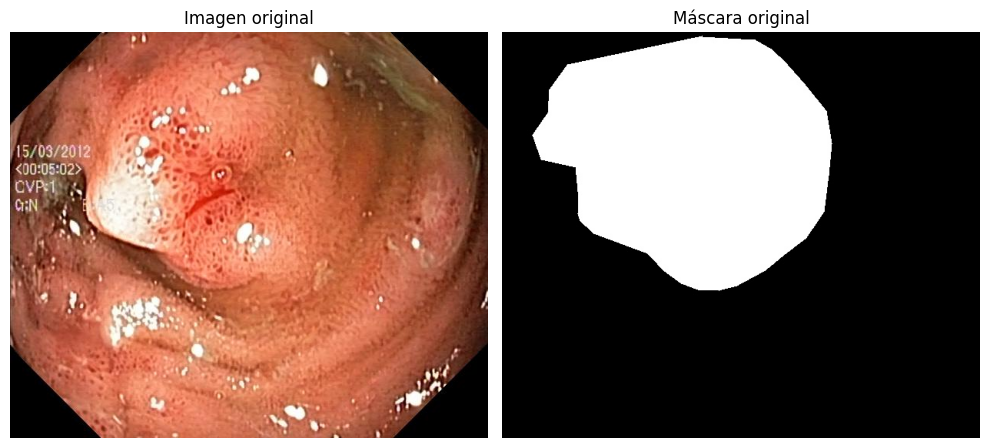

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

BASE_KVASIR = "/content/kvasir_seg/Kvasir-SEG"
RUTA_IMAGENES = os.path.join(BASE_KVASIR, "images")
RUTA_MASCARAS = os.path.join(BASE_KVASIR, "masks")

imagenes = sorted([
    f for f in os.listdir(RUTA_IMAGENES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

mascaras = sorted([
    f for f in os.listdir(RUTA_MASCARAS)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Cantidad de imágenes:", len(imagenes))
print("Cantidad de máscaras:", len(mascaras))
print("\nEjemplo de imagen:", imagenes[0])
print("Ejemplo de máscara:", mascaras[0])

# Mostrar una imagen y su máscara correspondiente
nombre = imagenes[0]
ruta_img = os.path.join(RUTA_IMAGENES, nombre)
ruta_mask = os.path.join(RUTA_MASCARAS, nombre)

img = Image.open(ruta_img).convert("RGB")
mask = Image.open(ruta_mask)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(img)
axs[0].set_title("Imagen original")
axs[0].axis("off")

axs[1].imshow(mask, cmap="gray")
axs[1].set_title("Máscara original")
axs[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Configuración para Kvasir-SEG
TAM = 128
NOMBRES_CLASES = ["Fondo", "Estructura"]
N_CLASES = len(NOMBRES_CLASES)

# Transformación de las imágenes
transform_img_kvasir = T.Compose([
    T.Resize((TAM, TAM)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Transformación de las máscaras: solo clases 0 y 1
def transform_mask_kvasir(mask):
    mask = mask.resize((TAM, TAM), resample=Image.NEAREST)
    mask_arr = np.array(mask.convert("L"))
    mask_arr = (mask_arr > 127).astype(np.int64)
    return torch.as_tensor(mask_arr, dtype=torch.long)


class KvasirDataset(Dataset):
    def __init__(self, ruta_imagenes, ruta_mascaras):
        self.ruta_imagenes = ruta_imagenes
        self.ruta_mascaras = ruta_mascaras

        extensiones = (".jpg", ".jpeg", ".png")
        self.nombres = sorted([
            f for f in os.listdir(ruta_imagenes)
            if f.lower().endswith(extensiones)
            and os.path.isfile(os.path.join(ruta_mascaras, f))
        ])

    def __len__(self):
        return len(self.nombres)

    def __getitem__(self, idx):
        nombre = self.nombres[idx]

        imagen = Image.open(
            os.path.join(self.ruta_imagenes, nombre)
        ).convert("RGB")

        mascara = Image.open(
            os.path.join(self.ruta_mascaras, nombre)
        )

        imagen = transform_img_kvasir(imagen)
        mascara = transform_mask_kvasir(mascara)

        return imagen, mascara


# Crear dataset
dataset_kvasir = KvasirDataset(
    RUTA_IMAGENES,
    RUTA_MASCARAS
)

# Separar entrenamiento y validación (80/20)
n_train = int(0.8 * len(dataset_kvasir))
n_val = len(dataset_kvasir) - n_train

train_ds_kvasir, val_ds_kvasir = torch.utils.data.random_split(
    dataset_kvasir,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader_kvasir = DataLoader(
    train_ds_kvasir,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader_kvasir = DataLoader(
    val_ds_kvasir,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Total de imágenes:", len(dataset_kvasir))
print("Entrenamiento:", len(train_ds_kvasir))
print("Validación:", len(val_ds_kvasir))
print("Clases:", NOMBRES_CLASES)

Total de imágenes: 1000
Entrenamiento: 800
Validación: 200
Clases: ['Fondo', 'Estructura']


Forma de las imágenes: torch.Size([16, 3, 128, 128])
Forma de las máscaras: torch.Size([16, 128, 128])
Valores de las máscaras: tensor([0, 1])


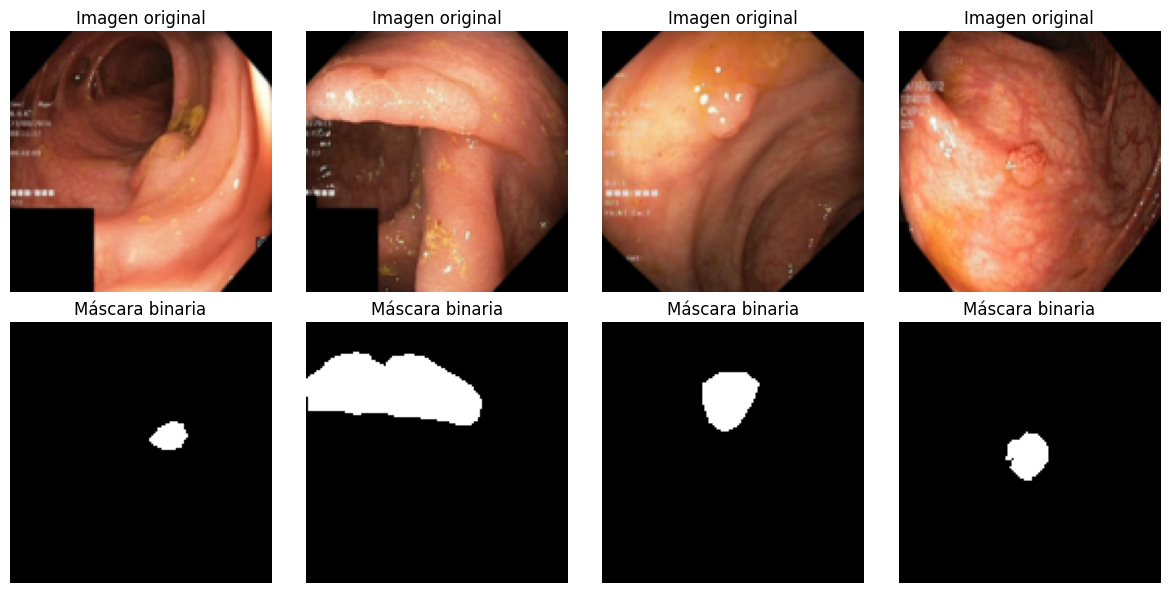

In [ ]:
# Revisar un lote del nuevo dataset
imgs_kvasir, masks_kvasir = next(iter(train_loader_kvasir))

print("Forma de las imágenes:", imgs_kvasir.shape)
print("Forma de las máscaras:", masks_kvasir.shape)
print("Valores de las máscaras:", torch.unique(masks_kvasir))

# Visualizar imágenes, máscaras reales y sus etiquetas
fig, axs = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs_kvasir[i]))
    axs[0, i].set_title("Imagen original")
    axs[0, i].axis("off")

    axs[1, i].imshow(masks_kvasir[i].numpy(), cmap="gray", vmin=0, vmax=1)
    axs[1, i].set_title("Máscara binaria")
    axs[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Crear una U-Net nueva para las 2 clases
modelo = UNetCompacta(
    in_channels=3,
    num_classes=N_CLASES
).to(DEVICE)

# Entrenamiento
EPOCHS = 6
optimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=1e-3
)

print("--- Entrenamiento U-Net con Kvasir-SEG ---")

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    modelo.train()
    loss_acumulada = 0.0

    for imgs, masks in train_loader_kvasir:
        imgs = imgs.to(DEVICE)
        masks = masks.to(DEVICE).long()

        optimizador.zero_grad()
        logits = modelo(imgs)
        loss = loss_combinada(logits, masks)

        loss.backward()
        optimizador.step()

        loss_acumulada += loss.item()

    loss_promedio = loss_acumulada / len(train_loader_kvasir)
    tiempo_epoca = time.time() - t0

    print(
        f"Época {epoch}/{EPOCHS} | "
        f"Loss: {loss_promedio:.4f} | "
        f"Tiempo: {tiempo_epoca:.1f}s"
    )

--- Entrenamiento U-Net con Kvasir-SEG ---
Época 1/6 | Loss: 0.8083 | Tiempo: 6.9s
Época 2/6 | Loss: 0.6657 | Tiempo: 7.5s
Época 3/6 | Loss: 0.6235 | Tiempo: 5.3s
Época 4/6 | Loss: 0.5700 | Tiempo: 5.3s
Época 5/6 | Loss: 0.5324 | Tiempo: 5.2s
Época 6/6 | Loss: 0.4834 | Tiempo: 5.3s


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

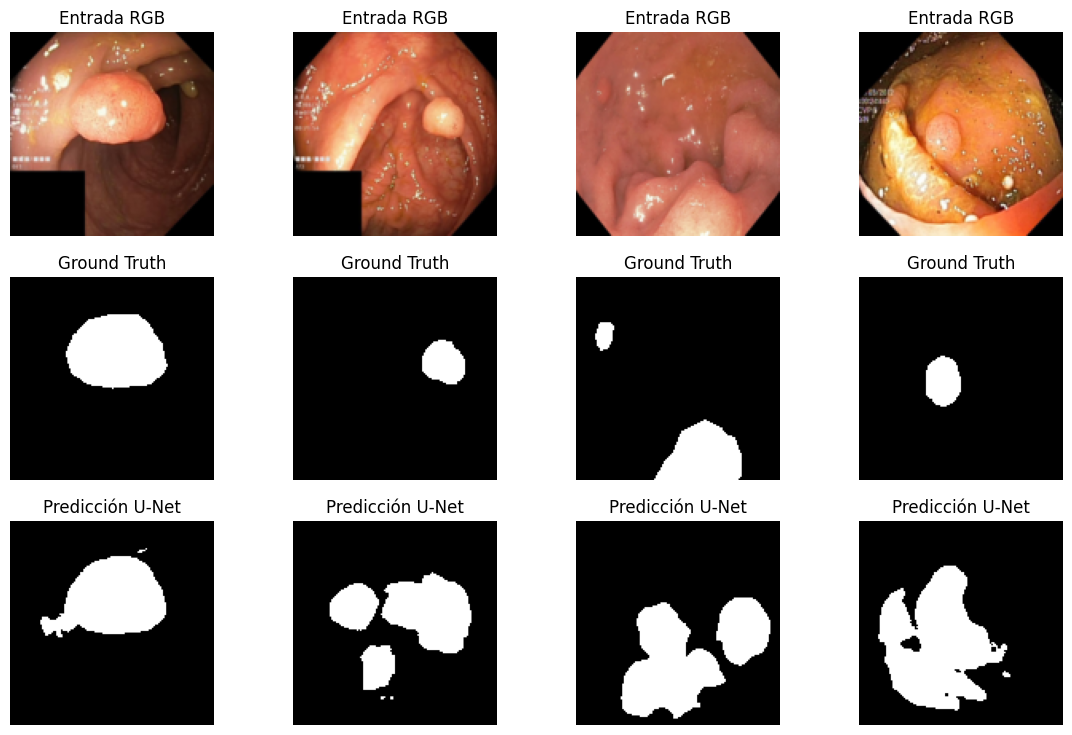

In [ ]:
# Visualización: imagen original, máscara real y predicción U-Net
imgs, masks = next(iter(val_loader_kvasir))
imgs_dev = imgs.to(DEVICE)

modelo.eval()
with torch.no_grad():
    preds = modelo(imgs_dev).argmax(dim=1).cpu()

fig, axs = plt.subplots(3, 4, figsize=(14, 9))

for i in range(4):
    # Fila 1: imagen original
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    # Fila 2: máscara real
    axs[1, i].imshow(
        masks[i].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axs[1, i].set_title("Ground Truth")
    axs[1, i].axis("off")

    # Fila 3: predicción del modelo
    axs[2, i].imshow(
        preds[i].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axs[2, i].set_title("Predicción U-Net")
    axs[2, i].axis("off")

plt

In [ ]:
# Métricas para las 2 clases
metric_iou_clase = MulticlassJaccardIndex(
    num_classes=N_CLASES,
    average=None
).to(DEVICE)

metric_iou_macro = MulticlassJaccardIndex(
    num_classes=N_CLASES,
    average="macro"
).to(DEVICE)

metric_confusion = MulticlassConfusionMatrix(
    num_classes=N_CLASES
).to(DEVICE)

# Evaluación sobre el conjunto de validación
modelo.eval()

with torch.no_grad():
    for imgs, masks in val_loader_kvasir:
        imgs = imgs.to(DEVICE)
        masks = masks.to(DEVICE).long()

        logits = modelo(imgs)
        preds = logits.argmax(dim=1)

        metric_iou_clase.update(preds, masks)
        metric_iou_macro.update(preds, masks)
        metric_confusion.update(preds, masks)

# Resultados
ious = metric_iou_clase.compute().cpu().numpy()
miou = metric_iou_macro.compute().item()
cm = metric_confusion.compute().cpu().numpy()

tabla_eval_kvasir = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "IoU (Jaccard)": np.round(ious, 4)
})

display(tabla_eval_kvasir)
print(f"\nmIoU: {miou:.4f}")
print("\nMatriz de confusión:")
print(cm)

,Clase,IoU (Jaccard)
0,Fondo,0.8733
1,Estructura,0.4772



mIoU: 0.6752

Matriz de confusión:
[[2564942  193783]
 [ 178378  339697]]


Entrené la U-Net con el nuevo dataset por 6 épocas y la pérdida pasó de 0.80 a 0.48. Al evaluarla, obtuvo un IoU de 0.8733 para el fondo y 0.4772 para la estructura, con un mIoU de 0.6752. Es decir, el modelo reconoce mejor el fondo que la estructura.
